# Amazon Review Triage: Final Run

**Team 3: Jolie Walker and Cooper Gunnels. Industry AI Challenge, From Pre-trained Model to Business Solution.**

This notebook is the final, end-to-end run of the project. It repeats the initial four-run study with the same data, model, splits and experiment definitions, and adds the evaluation steps the initial run was missing:

- best-epoch checkpoint selection on validation loss (the initial run kept the last epoch, and Experiment 1 was overfitting by then)
- bootstrap confidence intervals and paired comparisons against the baseline
- a seed-stability check for the baseline and the selected configuration
- decision-threshold tuning on validation data to meet the business recall target
- end-to-end inference timing on GPU and on CPU, plus model size
- token-length analysis to explain the 256-token experiment
- behavior on 3-star (mixed) reviews the model never saw in training
- structured error analysis (by star rating, length and confidence) with an export for manual review
- a single, final evaluation on the untouched test set after every choice is fixed

`CHANGES.md` in the repository lists each change and the reason for it. The initial run is preserved unchanged in `Amazon_Review_Sentiment_Analysis.ipynb`.

**To run:** Runtime > Change runtime type > T4 GPU, then Runtime > Run all. Expected time is roughly 40 to 60 minutes. All outputs are written to `final_run/` and downloaded as `final_run_evidence.zip` at the end.

## 1. Business context

**Client.** The customer experience (CX) team at an online retailer. The team receives far more free-text customer feedback (reviews, survey comments, support messages) than it can read, and unhappy customers who are not contacted quickly are more likely to return products, leave, or post publicly.

**Proposed solution.** A text classifier that flags likely-negative feedback so a CX agent reviews it first. A person still makes every decision; the model only sets the reading order.

**Primary metric: recall on the negative class.** A missed unhappy customer (false negative) costs more than a false flag, which an agent dismisses in seconds. Precision on the negative class is tracked as the secondary metric, because too many false flags waste agent time. We also report the *flag rate* (share of all feedback flagged), which is the agent workload.

**Business success criterion.** Catch at least `TARGET_NEG_RECALL` of negative feedback (set in the configuration cell below, before the run), while keeping negative precision high enough that most flags are worth reading.

**Operational constraint.** The model should be usable without a dedicated GPU, so we measure end-to-end CPU latency and throughput in addition to GPU speed.

**Dataset limitation.** Labels come from star ratings, which are a proxy for sentiment. Neutral 3-star reviews are removed from training. Product reviews are not identical to support messages, so a pilot on the client's own text would be required.

## 2. Setup and configuration

Every run shares the values in this cell unless an experiment deliberately changes one of them. `TARGET_NEG_RECALL` is the business requirement and must be fixed before running; it is used only to choose the decision threshold on validation data.

In [1]:
!pip install -q datasets transformers accelerate scikit-learn

In [2]:
import os, gc, time, json, copy, shutil, zipfile, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import datasets, transformers, sklearn
from datasets import load_dataset, DatasetDict, concatenate_datasets
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    set_seed,
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve,
)

# Shared settings (identical to the initial run)
SEED = 42
MODEL_NAME = "distilbert-base-uncased"
BASE_MAX_LEN = 128
TRAIN_SIZE = 16000
VAL_SIZE = 2000
EPOCHS = 3
TRAIN_BATCH = 16
EVAL_BATCH = 64
BASE_LR = 2e-4

# Business requirement, fixed BEFORE this run: share of negative feedback the
# system must catch. Used only to pick the decision threshold on validation data.
TARGET_NEG_RECALL = 0.90

# Stability check: retrain the baseline and the selected configuration with
# extra seeds to see how much results move from training randomness alone.
RUN_SEED_CHECK = True
EXTRA_SEEDS = [7, 123]

N_BOOTSTRAP = 2000
OUT = "final_run"
RUN_DIR = "runs"
os.makedirs(OUT, exist_ok=True)

set_seed(SEED)
assert torch.cuda.is_available(), "Switch the Colab runtime to a T4 GPU before running."
print("torch", torch.__version__, "| transformers", transformers.__version__,
      "| datasets", datasets.__version__, "| scikit-learn", sklearn.__version__)
print("GPU:", torch.cuda.get_device_name(0))

torch 2.14.1+cu130 | transformers 5.22.1 | datasets 4.8.5 | scikit-learn 1.6.1
GPU: Tesla T4


## 3. Data

Amazon Reviews Multi (English): 200,000 training, 5,000 validation and 5,000 test reviews, balanced across 1 to 5 stars. We map 1 to 2 stars to **negative (label 0)** and 4 to 5 stars to **positive (label 1)**, remove 3-star reviews, and remove duplicate review text within and across splits so no review can appear in both training and evaluation.

In [3]:
dataset = load_dataset("goosmanlei/amazon_reviews_multi", "en")
print(dataset)

for split in ["train", "validation", "test"]:
    counts = pd.Series(dataset[split]["stars"]).value_counts().sort_index()
    print(f"\n{split.upper()} star ratings:\n{counts.to_string()}")

README.md:   0%|          | 0.00/2.62k [00:00<?, ?B/s]

en/train.jsonl.gz: reconstructing file:   0%|          |  0.00B / 21.5MB            

en/train.jsonl.gz: downloading bytes:           |  0.00B            

en/validation.jsonl.gz: reconstructing file:   0%|          |  0.00B /  542kB            

en/validation.jsonl.gz: downloading bytes:           |  0.00B            

en/test.jsonl.gz: reconstructing file:   0%|          |  0.00B /  536kB            

en/test.jsonl.gz: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/200000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category'],
        num_rows: 200000
    })
    validation: Dataset({
        features: ['review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category'],
        num_rows: 5000
    })
    test: Dataset({
        features: ['review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category'],
        num_rows: 5000
    })
})

TRAIN star ratings:
1    40000
2    40000
3    40000
4    40000
5    40000

VALIDATION star ratings:
1    1000
2    1000
3    1000
4    1000
5    1000

TEST star ratings:
1    1000
2    1000
3    1000
4    1000
5    1000


In [4]:
def prepare_review(example):
    example["label"] = 0 if example["stars"] <= 2 else 1   # 0 = negative, 1 = positive
    example["clean_text"] = " ".join(example["review_body"].lower().split())
    return example

binary = DatasetDict({
    split: dataset[split].filter(lambda x: x["stars"] != 3).map(prepare_review)
    for split in ["train", "validation", "test"]
})

# Remove repeated review text. Work from test backward so the evaluation
# splits keep every review they can and training loses the overlaps.
seen = set()
cleaned = DatasetDict()
for split in ["test", "validation", "train"]:
    keep = []
    for i, text in enumerate(binary[split]["clean_text"]):
        if text not in seen:
            keep.append(i)
            seen.add(text)
    cleaned[split] = binary[split].select(keep)
    print(f"{split}: {len(binary[split])} -> {len(cleaned[split])} reviews")

for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    assert not set(cleaned[a]["clean_text"]) & set(cleaned[b]["clean_text"])
print("\nNo review text is shared between splits.")

for split in ["train", "validation", "test"]:
    lab = np.array(cleaned[split]["label"])
    print(f"{split}: negative={int((lab == 0).sum())}  positive={int((lab == 1).sum())}")

Filter:   0%|          | 0/200000 [00:00<?, ? examples/s]

Map:   0%|          | 0/160000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/5000 [00:00<?, ? examples/s]

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/5000 [00:00<?, ? examples/s]

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

test: 4000 -> 4000 reviews
validation: 4000 -> 3998 reviews
train: 160000 -> 159401 reviews

No review text is shared between splits.
train: negative=79759  positive=79642
validation: negative=1999  positive=1999
test: negative=2000  positive=2000


The initial run's speed check (1,000 reviews, one epoch, about 5 seconds) showed that a 16,000-review balanced training sample keeps each experiment well under the 30-minute limit. We use the same sample sizes and the same sampling seed, so every run trains and validates on identical reviews. The test set is the full deduplicated test split.

In [5]:
def balanced_sample(data, total, seed=SEED):
    negatives = data.filter(lambda x: x["label"] == 0).shuffle(seed=seed).select(range(total // 2))
    positives = data.filter(lambda x: x["label"] == 1).shuffle(seed=seed).select(range(total // 2))
    return concatenate_datasets([negatives, positives]).shuffle(seed=seed)

experiment_data = DatasetDict({
    "train": balanced_sample(cleaned["train"], TRAIN_SIZE),
    "validation": balanced_sample(cleaned["validation"], VAL_SIZE),
    "test": cleaned["test"],
})
for split in experiment_data:
    print(f"{split}: {len(experiment_data[split])} reviews")

y_val = np.array(experiment_data["validation"]["label"], dtype=np.int8)
y_test = np.array(experiment_data["test"]["label"], dtype=np.int8)

Filter:   0%|          | 0/159401 [00:00<?, ? examples/s]

Filter:   0%|          | 0/159401 [00:00<?, ? examples/s]

Filter:   0%|          | 0/3998 [00:00<?, ? examples/s]

Filter:   0%|          | 0/3998 [00:00<?, ? examples/s]

train: 16000 reviews
validation: 2000 reviews
test: 4000 reviews


### 3.1 Review length in tokens

Experiment 3 raises the input limit from 128 to 256 tokens. Its effect can only be as large as the share of reviews that are actually longer than 128 tokens, so we measure that first.

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (585 > 512). Running this sequence through the model will result in indexing errors


,Reviews,Median tokens,90th percentile,95th percentile,99th percentile,Share over 128 tokens,Share over 256 tokens
0,16000,31,88,116,195,0.037875,0.004188


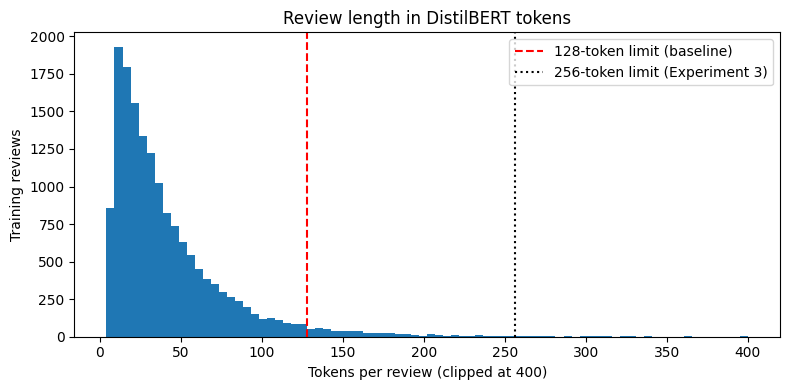

In [6]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def token_lengths(texts):
    return np.array([len(ids) for ids in tokenizer(list(texts), truncation=False)["input_ids"]])

train_lengths = token_lengths(experiment_data["train"]["review_body"])
val_lengths = token_lengths(experiment_data["validation"]["review_body"])

token_stats = pd.DataFrame([{
    "Reviews": len(train_lengths),
    "Median tokens": int(np.median(train_lengths)),
    "90th percentile": int(np.percentile(train_lengths, 90)),
    "95th percentile": int(np.percentile(train_lengths, 95)),
    "99th percentile": int(np.percentile(train_lengths, 99)),
    "Share over 128 tokens": float((train_lengths > 128).mean()),
    "Share over 256 tokens": float((train_lengths > 256).mean()),
}])
display(token_stats)
token_stats.to_csv(f"{OUT}/token_length_stats.csv", index=False)

plt.figure(figsize=(8, 4))
plt.hist(np.clip(train_lengths, 0, 400), bins=80)
plt.axvline(128, color="red", linestyle="--", label="128-token limit (baseline)")
plt.axvline(256, color="black", linestyle=":", label="256-token limit (Experiment 3)")
plt.xlabel("Tokens per review (clipped at 400)")
plt.ylabel("Training reviews")
plt.title("Review length in DistilBERT tokens")
plt.legend()
plt.tight_layout()
plt.savefig(f"{OUT}/token_length_histogram.png", dpi=300, bbox_inches="tight")
plt.show()

In [7]:
def tokenize_with(max_len):
    def fn(batch):
        return tokenizer(batch["review_body"], truncation=True, max_length=max_len)
    return fn

tok = {length: experiment_data.map(tokenize_with(length), batched=True) for length in [128, 256]}
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
print("Tokenized at 128 and 256 tokens.")

Map:   0%|          | 0/16000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

Map:   0%|          | 0/16000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

Tokenized at 128 and 256 tokens.


## 4. Evaluation helpers

All metrics treat **negative** as the class of interest. `p_neg` is the model's probability that a review is negative; a review is flagged when `p_neg >= threshold` (0.5 matches the usual argmax prediction).

Uncertainty comes from bootstrapping the validation or test reviews 2,000 times. When two runs are compared, the same resampled reviews are used for both (a paired bootstrap), which is the right test for "is this change better than the baseline on these reviews".

In [8]:
def softmax_np(logits):
    z = logits - logits.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def predict_neg_prob(trainer, ds):
    return softmax_np(trainer.predict(ds).predictions)[:, 0]

def predict_at(p_neg, threshold=0.5):
    return np.where(p_neg >= threshold, 0, 1).astype(np.int8)

def neg_metrics(y, pred):
    return {
        "Accuracy": accuracy_score(y, pred),
        "Negative Precision": precision_score(y, pred, pos_label=0, zero_division=0),
        "Negative Recall": recall_score(y, pred, pos_label=0, zero_division=0),
        "Negative F1": f1_score(y, pred, pos_label=0, zero_division=0),
        "Flag Rate": float((pred == 0).mean()),
    }

def _counts(Y, P):
    tp = ((Y == 0) & (P == 0)).sum(axis=-1)
    fp = ((Y == 1) & (P == 0)).sum(axis=-1)
    fn = ((Y == 0) & (P == 1)).sum(axis=-1)
    return tp, fp, fn

def _rates(tp, fp, fn):
    f1 = 2 * tp / np.maximum(2 * tp + fp + fn, 1)
    recall = tp / np.maximum(tp + fn, 1)
    precision = tp / np.maximum(tp + fp, 1)
    return f1, recall, precision

def _ci(values):
    return float(np.percentile(values, 2.5)), float(np.percentile(values, 97.5))

def bootstrap_ci(y, pred, n_boot=N_BOOTSTRAP, seed=SEED):
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(y), size=(n_boot, len(y)))
    f1, rec, prec = _rates(*_counts(y[idx], pred[idx]))
    return {"f1": _ci(f1), "recall": _ci(rec), "precision": _ci(prec)}

def paired_f1_diff(y, pred_a, pred_b, n_boot=N_BOOTSTRAP, seed=SEED):
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(y), size=(n_boot, len(y)))
    f1_a = _rates(*_counts(y[idx], pred_a[idx]))[0]
    f1_b = _rates(*_counts(y[idx], pred_b[idx]))[0]
    d = f1_b - f1_a
    lo, hi = _ci(d)
    return {"mean": float(d.mean()), "lo": lo, "hi": hi}

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    m = neg_metrics(labels, np.argmax(logits, axis=-1))
    return {"accuracy": m["Accuracy"], "neg_precision": m["Negative Precision"],
            "neg_recall": m["Negative Recall"], "neg_f1": m["Negative F1"]}

print("Helpers ready.")

Helpers ready.


### 4.1 Simple benchmark

On a balanced dataset the majority-class benchmark is "flag everything as negative": perfect recall, 50% precision, and a 100% flag rate. Any useful model must beat it on precision and F1 while keeping recall high.

In [9]:
benchmark_rows = []
for split_name, y in [("validation", y_val), ("test", y_test)]:
    pred = np.zeros(len(y), dtype=np.int8)
    benchmark_rows.append({"Split": split_name, **neg_metrics(y, pred)})
benchmark = pd.DataFrame(benchmark_rows)
display(benchmark.round(4))
benchmark.to_csv(f"{OUT}/majority_benchmark.csv", index=False)

,Split,Accuracy,Negative Precision,Negative Recall,Negative F1,Flag Rate
0,validation,0.5,0.5,1.0,0.6667,1.0
1,test,0.5,0.5,1.0,0.6667,1.0


## 5. Controlled experiments

One function trains every configuration so the only differences between runs are the arguments passed in. Compared with the initial run, there is one protocol change applied to **every** run equally: checkpoints are saved each epoch and the epoch with the **lowest validation loss** is kept (`load_best_model_at_end`). In the initial run, Experiment 1's validation loss rose every epoch after the first while its training loss halved, so the last epoch was not the best model.

Validation loss is used for checkpoint choice, not F1, because F1 at the fixed 0.5 threshold swung by several points between epochs (the baseline's recall went 0.845, 0.919, 0.870) mainly through threshold drift. Loss measures the quality of the probabilities themselves, and the threshold is tuned separately in Section 7.

In [10]:
def count_params(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)

def epoch_table(trainer):
    train_loss, evals = {}, {}
    for entry in trainer.state.log_history:
        if "epoch" not in entry:
            continue
        ep = int(round(entry["epoch"]))
        if "loss" in entry and ep not in train_loss:
            train_loss[ep] = entry["loss"]
        if "eval_loss" in entry and ep not in evals:
            evals[ep] = entry
    rows = []
    for ep in sorted(evals):
        ev = evals[ep]
        rows.append({
            "Epoch": ep,
            "Training Loss": train_loss.get(ep, np.nan),
            "Validation Loss": ev["eval_loss"],
            "Accuracy": ev.get("eval_accuracy"),
            "Neg Precision": ev.get("eval_neg_precision"),
            "Neg Recall": ev.get("eval_neg_recall"),
            "Neg F1": ev.get("eval_neg_f1"),
        })
    return pd.DataFrame(rows)

def train_run(run_name, unfreeze_last_n=0, lr=BASE_LR, max_len=BASE_MAX_LEN, seed=SEED):
    set_seed(seed)
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)

    # Freeze the pre-trained encoder, then optionally unfreeze its top layers.
    for p in model.distilbert.parameters():
        p.requires_grad = False
    if unfreeze_last_n > 0:
        for layer in model.distilbert.transformer.layer[-unfreeze_last_n:]:
            for p in layer.parameters():
                p.requires_grad = True

    out_dir = os.path.join(RUN_DIR, f"{run_name.replace(' ', '_').lower()}_seed{seed}")
    args = TrainingArguments(
        output_dir=out_dir,
        num_train_epochs=EPOCHS,
        per_device_train_batch_size=TRAIN_BATCH,
        per_device_eval_batch_size=EVAL_BATCH,
        learning_rate=lr,
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="eval_loss",
        greater_is_better=False,
        save_total_limit=2,
        report_to="none",
        seed=seed,
        data_seed=seed,
    )
    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=tok[max_len]["train"],
        eval_dataset=tok[max_len]["validation"],
        data_collator=data_collator,
        processing_class=tokenizer,
        compute_metrics=compute_metrics,
    )

    start = time.time()
    trainer.train()
    minutes = (time.time() - start) / 60

    log = epoch_table(trainer)
    best_epoch = int(log.loc[log["Validation Loss"].idxmin(), "Epoch"])
    p_val = predict_neg_prob(trainer, tok[max_len]["validation"])

    shutil.rmtree(out_dir, ignore_errors=True)   # best weights are already loaded in memory

    return {
        "trainer": trainer, "seed": seed, "max_len": max_len, "lr": lr,
        "unfreeze_last_n": unfreeze_last_n, "minutes": minutes,
        "trainable_params": count_params(trainer.model, trainable_only=True),
        "total_params": count_params(trainer.model),
        "epoch_log": log, "best_epoch": best_epoch, "p_val": p_val,
    }

### 5.1 Run definitions

These are the same four configurations as the initial run. Each experiment changes exactly one setting relative to the baseline.

In [11]:
EXPERIMENTS = [
    dict(
        name="Baseline",
        change="Initial configuration: frozen DistilBERT encoder, train classifier head only (LR 2e-4, 128 tokens)",
        reason="Establish a cheap reference that uses the pre-trained language features as-is",
        expected="Clearly above the majority benchmark, but limited because the encoder cannot adapt to review language",
        tradeoff="Cheapest option to train; fewest trainable weights",
        kwargs=dict(),
    ),
    dict(
        name="Experiment 1",
        change="Unfreeze the last 2 transformer layers",
        reason="Let the top layers adapt to review-specific wording such as product complaints and mixed praise and criticism",
        expected="Higher F1, at the cost of more trainable weights, longer training and more overfitting risk",
        tradeoff="More trainable weights and longer training; needs best-epoch selection to control overfitting",
        kwargs=dict(unfreeze_last_n=2),
    ),
    dict(
        name="Experiment 2",
        change="Lower the learning rate from 2e-4 to 5e-5",
        reason="5e-5 is a common transformer fine-tuning rate; tests whether the baseline rate is too aggressive",
        expected="Similar or slightly better results with smoother loss curves",
        tradeoff="Same cost as the baseline; may need more epochs to converge",
        kwargs=dict(lr=5e-5),
    ),
    dict(
        name="Experiment 3",
        change="Raise the maximum input length from 128 to 256 tokens",
        reason="Reviews longer than 128 tokens are cut off, and a complaint may appear late in a review",
        expected="Small gain, limited by how many reviews exceed 128 tokens (Section 3.1)",
        tradeoff="Longer inputs cost more compute in training and in every prediction",
        kwargs=dict(max_len=256),
    ),
]

runs = {}
for exp in EXPERIMENTS:
    print("=" * 70)
    print("Training:", exp["name"], "|", exp["change"])
    result = train_run(exp["name"], **exp["kwargs"])
    result.update(exp)
    runs[exp["name"]] = result
    print(f"Best epoch (lowest validation loss): {result['best_epoch']}  |  "
          f"training time {result['minutes']:.2f} min  |  "
          f"trainable weights {result['trainable_params'] / 1e6:.2f}M of {result['total_params'] / 1e6:.2f}M")
    display(result["epoch_log"].round(4))

Training: Baseline | Initial configuration: frozen DistilBERT encoder, train classifier head only (LR 2e-4, 128 tokens)


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Neg Precision,Neg Recall,Neg F1
1,0.373909,0.325614,0.851000,0.855263,0.845000,0.850101
2,0.328126,0.329131,0.857000,0.817616,0.919000,0.865348
3,0.315966,0.321704,0.856000,0.846304,0.870000,0.857988


... (28 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best epoch (lowest validation loss): 3  |  training time 4.57 min  |  trainable weights 0.59M of 66.96M


,Epoch,Training Loss,Validation Loss,Accuracy,Neg Precision,Neg Recall,Neg F1
0,1,0.3720,0.3233,0.8560,0.8655,0.843,0.8541
1,2,0.3301,0.3182,0.8625,0.8391,0.897,0.8671
2,3,0.3160,0.3156,0.8615,0.8527,0.874,0.8632


### 5.2 Experiment log

All metrics in this table are on **validation** data at the default 0.5 threshold, using each run's best epoch. The confidence interval column shows the plausible range of negative F1 given only 2,000 validation reviews. The last column compares each experiment to the baseline on the same resampled reviews: a change counts as a real improvement only if the whole interval is above zero.

In [12]:
base_pred = predict_at(runs["Baseline"]["p_val"])
log_rows = [{
    "Run": "Majority benchmark", "Change made": "Flag every review as negative",
    "Reason for change": "Simple reference any model must beat",
    "Expected result": "Recall 1.0, precision 0.5",
    **neg_metrics(y_val, np.zeros(len(y_val), dtype=np.int8)),
}]
for name, r in runs.items():
    pred = predict_at(r["p_val"])
    ci = bootstrap_ci(y_val, pred)
    row = {
        "Run": name,
        "Change made": r["change"],
        "Reason for change": r["reason"],
        "Expected result": r["expected"],
        "Trainable params (M)": round(r["trainable_params"] / 1e6, 2),
        "Best epoch": r["best_epoch"],
        "Validation loss": float(r["epoch_log"]["Validation Loss"].min()),
        **neg_metrics(y_val, pred),
        "Neg F1 95% CI": f"{ci['f1'][0]:.3f} to {ci['f1'][1]:.3f}",
        "Training minutes": round(r["minutes"], 2),
        "Practical trade-off": f"{r['tradeoff']} ({r['trainable_params'] / 1e6:.2f}M trainable weights, {r['minutes']:.1f} min)",
    }
    if name != "Baseline":
        d = paired_f1_diff(y_val, base_pred, pred)
        row["F1 change vs baseline (95% CI)"] = f"{d['mean']:+.3f} ({d['lo']:+.3f} to {d['hi']:+.3f})"
        row["Verdict vs baseline"] = ("better" if d["lo"] > 0 else
                                      "worse" if d["hi"] < 0 else
                                      "not distinguishable")
    log_rows.append(row)

experiment_log = pd.DataFrame(log_rows)
experiment_log.to_csv(f"{OUT}/experiment_log.csv", index=False)

summary_cols = ["Run", "Best epoch", "Trainable params (M)", "Negative F1", "Neg F1 95% CI",
                "Negative Recall", "Negative Precision", "Accuracy", "Validation loss",
                "Training minutes", "F1 change vs baseline (95% CI)", "Verdict vs baseline"]
display(experiment_log[summary_cols].round(4))

,Run,Best epoch,Trainable params (M),Negative F1,Neg F1 95% CI,Negative Recall,Negative Precision,Accuracy,Validation loss,Training minutes,F1 change vs baseline (95% CI),Verdict vs baseline
0,Majority benchmark,NaN,NaN,0.6667,NaN,1.000,0.5000,0.5000,NaN,NaN,NaN,NaN
1,Baseline,3.0,0.59,0.8580,0.841 to 0.874,0.870,0.8463,0.8560,0.3217,3.31,NaN,NaN
2,Experiment 1,1.0,14.77,0.8892,0.874 to 0.904,0.867,0.9126,0.8920,0.3061,5.36,+0.031 (+0.016 to +0.046),better
3,Experiment 2,3.0,0.59,0.8545,0.838 to 0.871,0.863,0.8461,0.8530,0.3332,3.66,-0.004 (-0.011 to +0.004),not distinguishable
4,Experiment 3,3.0,0.59,0.8632,0.847 to 0.880,0.874,0.8527,0.8615,0.3156,4.57,+0.005 (+0.000 to +0.011),better


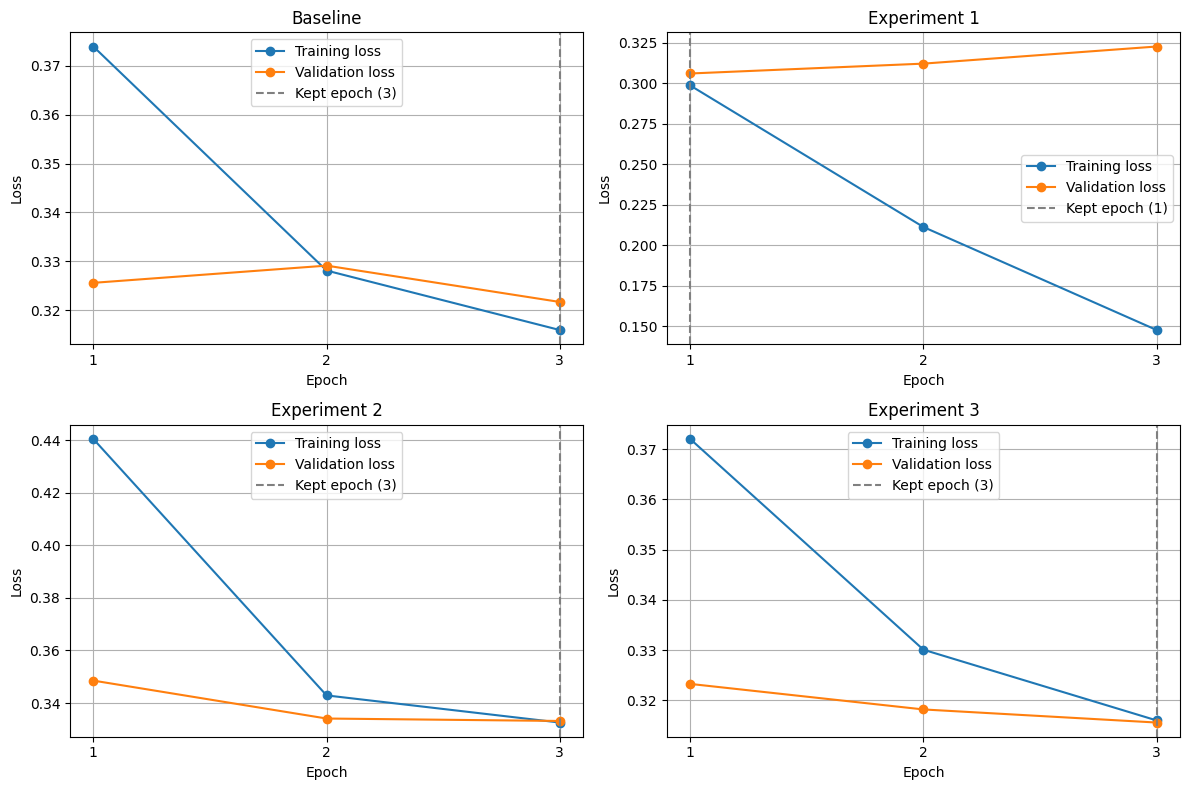

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (name, r) in zip(axes.flat, runs.items()):
    log = r["epoch_log"]
    ax.plot(log["Epoch"], log["Training Loss"], marker="o", label="Training loss")
    ax.plot(log["Epoch"], log["Validation Loss"], marker="o", label="Validation loss")
    ax.axvline(r["best_epoch"], color="gray", linestyle="--", label=f"Kept epoch ({r['best_epoch']})")
    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.set_xticks(log["Epoch"])
    ax.grid(True)
    ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT}/training_validation_curves.png", dpi=300, bbox_inches="tight")
plt.show()

**Interpretation (team to complete after the run).** For each experiment: what we expected, what happened, and what we learned. Note which experiment(s) are not distinguishable from the baseline, and use the token-length results in Section 3.1 to explain Experiment 3.

## 6. Model selection and stability

The configuration is chosen on **validation** results only. The cell below prints which run has the highest validation F1, but the team sets `SELECTED_RUN` explicitly so the choice can also weigh cost, overfitting and stability rather than the top number alone. If the results point to a different choice, change `SELECTED_RUN` and re-run from this cell down.

The seed check retrains the baseline and the selected configuration with two more random seeds (same data, same settings). If the gap between them is much larger than the spread across seeds, the improvement is not a lucky draw.

In [14]:
model_rows = experiment_log[experiment_log["Run"] != "Majority benchmark"]
best_by_f1 = model_rows.loc[model_rows["Negative F1"].idxmax(), "Run"]

SELECTED_RUN = "Experiment 1"

print("Highest validation negative F1:", best_by_f1)
print("Selected configuration:", SELECTED_RUN)
if best_by_f1 != SELECTED_RUN:
    print("NOTE: the selected run is not the top validation F1 run. Record the reason in the report.")
sel = runs[SELECTED_RUN]

Highest validation negative F1: Experiment 1
Selected configuration: Experiment 1


In [15]:
seed_rows = []
for name in dict.fromkeys(["Baseline", SELECTED_RUN]):
    r = runs[name]
    seed_rows.append({"Run": name, "Seed": SEED, "Best epoch": r["best_epoch"],
                      **neg_metrics(y_val, predict_at(r["p_val"]))})

if RUN_SEED_CHECK:
    for name in dict.fromkeys(["Baseline", SELECTED_RUN]):
        kwargs = runs[name]["kwargs"]
        for s in EXTRA_SEEDS:
            print(f"Seed check: {name}, seed {s}")
            extra = train_run(name, seed=s, **kwargs)
            seed_rows.append({"Run": name, "Seed": s, "Best epoch": extra["best_epoch"],
                              **neg_metrics(y_val, predict_at(extra["p_val"]))})
            del extra
            gc.collect()
            torch.cuda.empty_cache()

seed_table = pd.DataFrame(seed_rows)
seed_table.to_csv(f"{OUT}/seed_stability.csv", index=False)
display(seed_table.round(4))

seed_summary = (seed_table.groupby("Run")[["Negative F1", "Negative Recall", "Negative Precision", "Accuracy"]]
                .agg(["mean", "std"]).round(4))
seed_summary.to_csv(f"{OUT}/seed_stability_summary.csv")
display(seed_summary)

Seed check: Baseline, seed 7


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Neg Precision,Neg Recall,Neg F1
1,0.370683,0.327224,0.856000,0.860324,0.850000,0.855131
2,0.327883,0.319536,0.862500,0.858556,0.868000,0.863252
3,0.318995,0.318963,0.860500,0.844317,0.884000,0.863703


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (20 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

,Run,Seed,Best epoch,Accuracy,Negative Precision,Negative Recall,Negative F1,Flag Rate
0,Baseline,42,3,0.8560,0.8463,0.870,0.8580,0.5140
1,Experiment 1,42,1,0.8920,0.9126,0.867,0.8892,0.4750
2,Baseline,7,3,0.8605,0.8443,0.884,0.8637,0.5235
3,Baseline,123,3,0.8565,0.8554,0.858,0.8567,0.5015
4,Experiment 1,7,1,0.8730,0.9172,0.820,0.8659,0.4470
5,Experiment 1,123,1,0.8820,0.9099,0.848,0.8778,0.4660


Negative F1         Negative Recall         Negative Precision  \
                    mean     std            mean     std               mean   
Run                                                                           
Baseline          0.8595  0.0037          0.8707  0.0130             0.8487   
Experiment 1      0.8777  0.0117          0.8450  0.0236             0.9132   

                     Accuracy          
                 std     mean     std  
Run                                    
Baseline      0.0059   0.8577  0.0025  
Experiment 1  0.0037   0.8823  0.0095

## 7. Decision threshold for the business target

A 0.5 threshold is arbitrary from the client's point of view. Here we choose the threshold on **validation** data: the highest threshold that still catches at least `TARGET_NEG_RECALL` of negative reviews. A higher threshold flags fewer reviews, so this is the setting that meets the recall target with the least agent workload. The table shows how precision, recall and flag rate trade off at nearby thresholds.

Chosen threshold: p_neg >= 0.4163 (target negative recall 0.9)


,Threshold,Chosen,Accuracy,Negative Precision,Negative Recall,Negative F1,Flag Rate
0,0.2000,False,0.8955,0.8645,0.938,0.8998,0.5425
1,0.3000,False,0.8975,0.8775,0.924,0.9001,0.5265
2,0.4000,False,0.8985,0.8965,0.901,0.8988,0.5025
3,0.4163,True,0.8990,0.8982,0.900,0.8991,0.5010
4,0.5000,False,0.8920,0.9126,0.867,0.8892,0.4750
5,0.6000,False,0.8825,0.9264,0.831,0.8761,0.4485
6,0.7000,False,0.8710,0.9365,0.796,0.8605,0.4250
7,0.8000,False,0.8500,0.9442,0.744,0.8322,0.3940


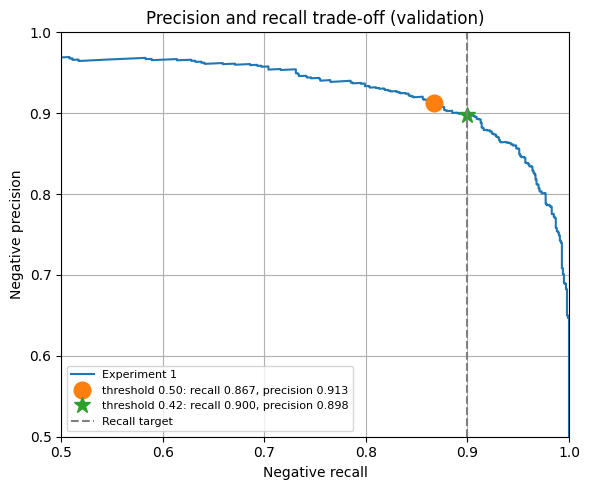

In [16]:
p_val_sel = sel["p_val"]
precisions, recalls, thresholds = precision_recall_curve(y_val == 0, p_val_sel)
meets_target = recalls[:-1] >= TARGET_NEG_RECALL
CHOSEN_T = float(thresholds[meets_target].max())
print(f"Chosen threshold: p_neg >= {CHOSEN_T:.4f} (target negative recall {TARGET_NEG_RECALL})")

threshold_rows = []
for t in sorted(set([0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, round(CHOSEN_T, 4)])):
    threshold_rows.append({"Threshold": t, "Chosen": t == round(CHOSEN_T, 4),
                           **neg_metrics(y_val, predict_at(p_val_sel, t))})
threshold_table = pd.DataFrame(threshold_rows)
threshold_table.to_csv(f"{OUT}/threshold_table_validation.csv", index=False)
display(threshold_table.round(4))

plt.figure(figsize=(6, 5))
plt.plot(recalls, precisions, label=SELECTED_RUN)
for t, style in [(0.5, "o"), (CHOSEN_T, "*")]:
    m = neg_metrics(y_val, predict_at(p_val_sel, t))
    plt.plot(m["Negative Recall"], m["Negative Precision"], style, markersize=12,
             label=f"threshold {t:.2f}: recall {m['Negative Recall']:.3f}, precision {m['Negative Precision']:.3f}")
plt.axvline(TARGET_NEG_RECALL, color="gray", linestyle="--", label="Recall target")
plt.xlabel("Negative recall")
plt.ylabel("Negative precision")
plt.title("Precision and recall trade-off (validation)")
plt.xlim(0.5, 1.0)
plt.ylim(0.5, 1.0)
plt.grid(True)
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{OUT}/precision_recall_validation.png", dpi=300, bbox_inches="tight")
plt.show()

## 8. Error analysis (validation)

The initial run looked at the first three errors of each type. Here every validation error at the chosen threshold is exported, and errors are broken down by star rating, review length and model confidence to look for patterns. `validation_errors.csv` has an empty `manual_category` column for the team to label a sample of errors by hand (for example: mixed sentiment, off-topic complaint, sarcasm, label noise).

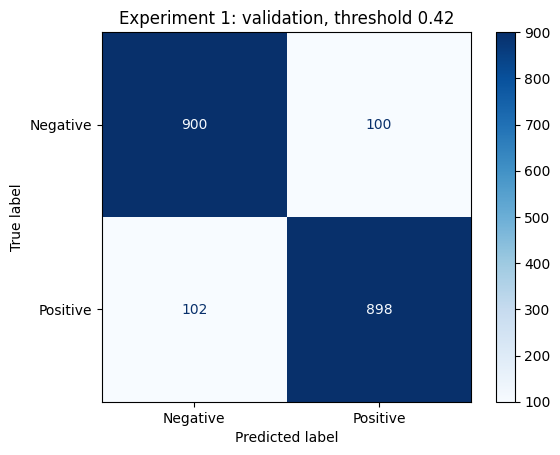

Errors: 202 of 2000
error_type
False alarm        102
Missed negative    100

Error rate by star rating:


,reviews,error_rate
stars,,
1,494,0.0628
2,506,0.1364
4,494,0.1579
5,506,0.0474


Error rate by review length (tokens):


,reviews,error_rate
length_bucket,,
1-32,1052,0.0979
33-64,569,0.0949
65-128,290,0.0931
over 128,89,0.2022


,Errors,Errors with confidence >= 0.9,Share of errors that were confident
0,202,71,0.3515


In [17]:
pred_val_sel = predict_at(p_val_sel, CHOSEN_T)

cm = confusion_matrix(y_val, pred_val_sel, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=["Negative", "Positive"]).plot(cmap="Blues", values_format="d")
plt.title(f"{SELECTED_RUN}: validation, threshold {CHOSEN_T:.2f}")
plt.savefig(f"{OUT}/validation_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

val_df = pd.DataFrame({
    "review_body": list(experiment_data["validation"]["review_body"]),
    "stars": list(experiment_data["validation"]["stars"]),
    "label": y_val,
    "predicted": pred_val_sel,
    "p_neg": p_val_sel,
    "tokens": val_lengths,
})
val_df["correct"] = val_df["label"] == val_df["predicted"]
val_df["error_type"] = np.select(
    [(val_df["label"] == 0) & (val_df["predicted"] == 1), (val_df["label"] == 1) & (val_df["predicted"] == 0)],
    ["Missed negative", "False alarm"], default="")
val_df["confidence_in_prediction"] = np.where(val_df["predicted"] == 0, val_df["p_neg"], 1 - val_df["p_neg"])
val_df["length_bucket"] = pd.cut(val_df["tokens"], bins=[0, 32, 64, 128, 10_000],
                                 labels=["1-32", "33-64", "65-128", "over 128"])

errors = val_df[~val_df["correct"]].copy()
errors["manual_category"] = ""
errors.sort_values("confidence_in_prediction", ascending=False).to_csv(f"{OUT}/validation_errors.csv", index=False)

print("Errors:", len(errors), "of", len(val_df))
print(errors["error_type"].value_counts().to_string())

by_stars = val_df.groupby("stars").agg(reviews=("correct", "size"), error_rate=("correct", lambda c: 1 - c.mean()))
by_length = val_df.groupby("length_bucket", observed=False).agg(reviews=("correct", "size"),
                                                                 error_rate=("correct", lambda c: 1 - c.mean()))
confident = pd.DataFrame([{
    "Errors": len(errors),
    "Errors with confidence >= 0.9": int((errors["confidence_in_prediction"] >= 0.9).sum()),
    "Share of errors that were confident": float((errors["confidence_in_prediction"] >= 0.9).mean()),
}])
by_stars.to_csv(f"{OUT}/error_rate_by_stars.csv")
by_length.to_csv(f"{OUT}/error_rate_by_length.csv")
confident.to_csv(f"{OUT}/confident_errors.csv", index=False)

print("\nError rate by star rating:")
display(by_stars.round(4))
print("Error rate by review length (tokens):")
display(by_length.round(4))
display(confident.round(4))

In [18]:
# Seeded random samples of each error type for the report (not just the first few).
for etype in ["Missed negative", "False alarm"]:
    subset = errors[errors["error_type"] == etype]
    sample = subset.sample(n=min(5, len(subset)), random_state=SEED)
    print("=" * 70)
    print(etype.upper())
    for _, row in sample.iterrows():
        print(f"\n{row['stars']} stars | p_neg = {row['p_neg']:.3f} | {row['tokens']} tokens")
        print(row["review_body"])

MISSED NEGATIVE

1 stars | p_neg = 0.318 | 10 tokens
Prettier in picture then in person

1 stars | p_neg = 0.060 | 9 tokens
Wish it was a little larger.

2 stars | p_neg = 0.002 | 155 tokens
This thing could give hearing to the deaf, or at least be in the standard rotation at an old folks home (for use Without Hearing Aids!) My brother owns one, but I failed to notice that he kept it in the basement play area. We purchased one for our 4-year old, who LOVES IT, but I can hardly think while in the same room. The default setting is NASA SHUTTLE LIFTOFF, and you need to turn down the volume every single time that the button on the touch pen is accidentally/purposefully hit (which is all the time). In conclusion: this is a great product with only one flaw: the default setting is LOUD AS HELL. If Oregon Scientific would change that, then this would be a 5 star toy.

1 stars | p_neg = 0.201 | 36 tokens
Makes my super sensitive skin chemical burn even when following the directions to a T. Only

**Interpretation (team to complete after the run).** Which star ratings and lengths cause most errors, what share of errors are confident (a sign of label noise or sarcasm), and what each error type would cost the CX team.

## 9. Behavior on mixed (3-star) feedback

3-star reviews were excluded from training, but real customer feedback includes mixed and neutral messages. This check shows how often the deployed system would flag them for an agent. It is not scored, because there is no correct label.

Filter:   0%|          | 0/5000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

,3-star reviews,Flagged as negative at chosen threshold,Flagged as negative at 0.5,Median p_neg
0,1000,0.615,0.556,0.5849


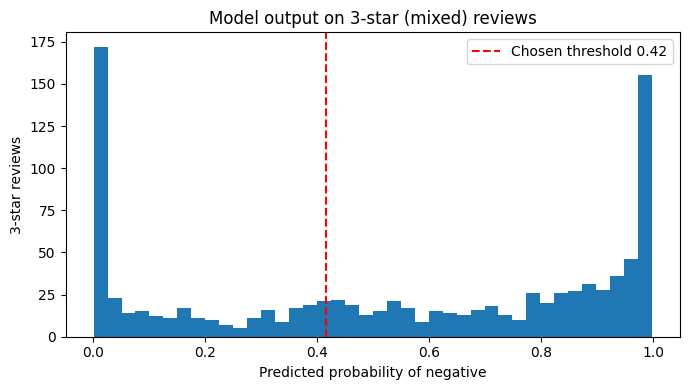

MOST NEGATIVE

p_neg = 0.998
My dog had this ball chewed up in a matter of a few hours. So disappointed in this Kong product.

p_neg = 0.998
Stopped working after a couple weeks of use : (

p_neg = 0.998
Very very disappointed because i didn't the assorted color of beads i only one color which is pink
MOST POSITIVE

p_neg = 0.001
Nice phone, great price

p_neg = 0.001
Great buy! Some of pieces were off slightly! Other then that she loves it!

p_neg = 0.001
made for very petite woman. good product for the pricing.quick delivery.
CLOSEST TO THRESHOLD

p_neg = 0.416
Really cute but you can get the same ones at the dollar store for 99 cents.

p_neg = 0.416
sad that these came with the lease looking like this. I ordered them in two colors and love the other pair

p_neg = 0.417
The shirt fits different than I had expected because it’s a lot shorter. I initially purchased two but but only gave a three star because they fit different than pictured and described. As far as the material they fee

In [19]:
three_star = dataset["validation"].filter(lambda x: x["stars"] == 3)
three_tok = three_star.map(tokenize_with(sel["max_len"]), batched=True)
p_three = predict_neg_prob(sel["trainer"], three_tok)

three_summary = pd.DataFrame([{
    "3-star reviews": len(p_three),
    "Flagged as negative at chosen threshold": float((p_three >= CHOSEN_T).mean()),
    "Flagged as negative at 0.5": float((p_three >= 0.5).mean()),
    "Median p_neg": float(np.median(p_three)),
}])
three_summary.to_csv(f"{OUT}/three_star_behavior.csv", index=False)
display(three_summary.round(4))

plt.figure(figsize=(7, 4))
plt.hist(p_three, bins=40)
plt.axvline(CHOSEN_T, color="red", linestyle="--", label=f"Chosen threshold {CHOSEN_T:.2f}")
plt.xlabel("Predicted probability of negative")
plt.ylabel("3-star reviews")
plt.title("Model output on 3-star (mixed) reviews")
plt.legend()
plt.tight_layout()
plt.savefig(f"{OUT}/three_star_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

texts_three = list(three_star["review_body"])
order = np.argsort(p_three)
for label, idxs in [("Most negative", order[-3:][::-1]), ("Most positive", order[:3]),
                    ("Closest to threshold", np.argsort(np.abs(p_three - CHOSEN_T))[:3])]:
    print("=" * 70)
    print(label.upper())
    for i in idxs:
        print(f"\np_neg = {p_three[i]:.3f}\n{texts_three[i]}")

## 10. Final evaluation on the test set

Everything is now fixed using validation data only: the configuration, its training epoch, and the decision threshold. The test set is evaluated **once** here. Results at the 0.5 threshold are shown for reference.

,Model,Test reviews,Accuracy,Negative Precision,Negative Recall,Negative F1,Flag Rate,Neg recall 95% CI,Neg precision 95% CI,Neg F1 95% CI
0,Majority benchmark,4000,0.5000,0.5000,1.0000,0.6667,1.0000,1.000 to 1.000,0.485 to 0.516,0.653 to 0.681
1,Experiment 1 at threshold 0.50,4000,0.9028,0.9255,0.8760,0.9001,0.4732,0.862 to 0.891,0.914 to 0.937,0.890 to 0.910
2,Experiment 1 at threshold 0.42 (chosen),4000,0.9028,0.9013,0.9045,0.9029,0.5018,0.891 to 0.916,0.888 to 0.914,0.894 to 0.912



Business criterion (negative recall >= 0.9): MET with recall 0.9045, precision 0.9013, flag rate 0.5018


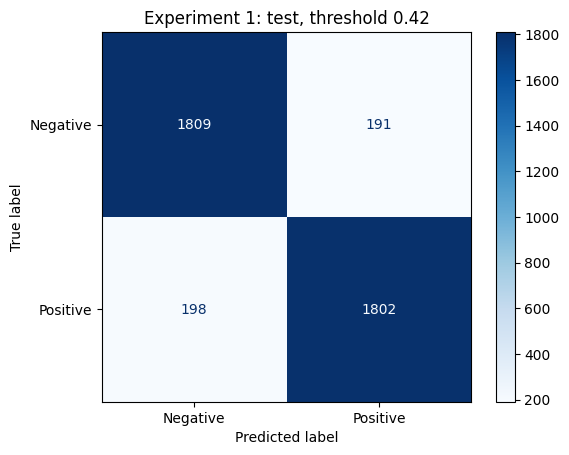

In [20]:
p_test = predict_neg_prob(sel["trainer"], tok[sel["max_len"]]["test"])
test_rows = []
for label, pred in [("Majority benchmark", np.zeros(len(y_test), dtype=np.int8)),
                    (f"{SELECTED_RUN} at threshold 0.50", predict_at(p_test, 0.5)),
                    (f"{SELECTED_RUN} at threshold {CHOSEN_T:.2f} (chosen)", predict_at(p_test, CHOSEN_T))]:
    ci = bootstrap_ci(y_test, pred)
    test_rows.append({
        "Model": label, "Test reviews": len(y_test), **neg_metrics(y_test, pred),
        "Neg recall 95% CI": f"{ci['recall'][0]:.3f} to {ci['recall'][1]:.3f}",
        "Neg precision 95% CI": f"{ci['precision'][0]:.3f} to {ci['precision'][1]:.3f}",
        "Neg F1 95% CI": f"{ci['f1'][0]:.3f} to {ci['f1'][1]:.3f}",
    })
final_test = pd.DataFrame(test_rows)
final_test.to_csv(f"{OUT}/final_test_results.csv", index=False)
display(final_test.round(4))

chosen = final_test.iloc[2]
met = chosen["Negative Recall"] >= TARGET_NEG_RECALL
print(f"\nBusiness criterion (negative recall >= {TARGET_NEG_RECALL}): "
      f"{'MET' if met else 'NOT MET'} with recall {chosen['Negative Recall']:.4f}, "
      f"precision {chosen['Negative Precision']:.4f}, flag rate {chosen['Flag Rate']:.4f}")

pred_test = predict_at(p_test, CHOSEN_T)
cm = confusion_matrix(y_test, pred_test, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=["Negative", "Positive"]).plot(cmap="Blues", values_format="d")
plt.title(f"{SELECTED_RUN}: test, threshold {CHOSEN_T:.2f}")
plt.savefig(f"{OUT}/test_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

## 11. Inference efficiency

Timing is end-to-end: tokenization plus the model forward pass, which is what a real service would do. Two modes are measured on both GPU and CPU: one review at a time (latency for a single incoming message) and batches of 32 (throughput for a backlog). The Colab CPU has very few cores, so CPU numbers are a conservative stand-in for an ordinary office machine or small cloud server.

In [21]:
SELECTED_MODEL_DIR = "selected_model"
sel["trainer"].save_model(SELECTED_MODEL_DIR)
tokenizer.save_pretrained(SELECTED_MODEL_DIR)
model_mb = sum(os.path.getsize(os.path.join(SELECTED_MODEL_DIR, f))
               for f in os.listdir(SELECTED_MODEL_DIR)) / 1e6

def time_inference(model, device, texts, max_len, batch_size, n_warmup=3):
    model = model.to(device).eval()
    def run(batch):
        enc = tokenizer(batch, padding=True, truncation=True, max_length=max_len,
                        return_tensors="pt").to(device)
        with torch.no_grad():
            out = model(**enc).logits
        if device.type == "cuda":
            torch.cuda.synchronize()
        return out
    for _ in range(n_warmup):
        run(texts[:batch_size])
    per_call = []
    start = time.perf_counter()
    for i in range(0, len(texts), batch_size):
        t0 = time.perf_counter()
        run(texts[i:i + batch_size])
        per_call.append(time.perf_counter() - t0)
    total = time.perf_counter() - start
    return {"Reviews timed": len(texts), "Batch size": batch_size,
            "Median ms per call": 1000 * float(np.median(per_call)),
            "Reviews per second": len(texts) / total}

timing_texts = list(experiment_data["validation"]["review_body"])
gpu = torch.device("cuda")
cpu = torch.device("cpu")
cpu_model = copy.deepcopy(sel["trainer"].model).to(cpu)
cpu_desc = f"Colab CPU ({os.cpu_count()} vCPU, {torch.get_num_threads()} threads)"

timing_rows = []
for hw_name, device, model, n_single, n_batch in [
        (torch.cuda.get_device_name(0), gpu, sel["trainer"].model, 200, 512),
        (cpu_desc, cpu, cpu_model, 100, 256)]:
    for bs, n in [(1, n_single), (32, n_batch)]:
        res = time_inference(model, device, timing_texts[:n], sel["max_len"], bs)
        timing_rows.append({"Hardware": hw_name, **res, "Includes tokenization": True})

inference_results = pd.DataFrame(timing_rows)
inference_results["Reviews per hour"] = inference_results["Reviews per second"] * 3600
inference_results["Model size (MB)"] = round(model_mb, 1)
inference_results["Total parameters (M)"] = round(sel["total_params"] / 1e6, 1)
inference_results.to_csv(f"{OUT}/inference_speed_results.csv", index=False)
display(inference_results.round(2))

sel["trainer"].model.to(gpu)
del cpu_model
gc.collect()

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

,Hardware,Reviews timed,Batch size,Median ms per call,Reviews per second,Includes tokenization,Reviews per hour,Model size (MB),Total parameters (M)
0,Tesla T4,200,1,4.98,180.49,True,649763.04,268.6,67.0
1,Tesla T4,512,32,118.34,275.36,True,991296.85,268.6,67.0
2,"Colab CPU (2 vCPU, 1 threads)",100,1,75.62,11.86,True,42702.18,268.6,67.0
3,"Colab CPU (2 vCPU, 1 threads)",256,32,3861.58,7.93,True,28553.37,268.6,67.0


10205

## 12. Save evidence

Writes the run configuration (library versions, settings, selected run and threshold) and packages every table and figure from `final_run/` into one zip. The trained model is zipped separately because it is large.

In [22]:
run_config = {
    "model": MODEL_NAME, "seed": SEED, "extra_seeds": EXTRA_SEEDS if RUN_SEED_CHECK else [],
    "train_size": TRAIN_SIZE, "val_size": VAL_SIZE, "test_size": int(len(y_test)),
    "epochs": EPOCHS, "train_batch": TRAIN_BATCH, "base_lr": BASE_LR, "base_max_len": BASE_MAX_LEN,
    "checkpoint_selection": "lowest validation loss (load_best_model_at_end)",
    "target_neg_recall": TARGET_NEG_RECALL, "selected_run": SELECTED_RUN,
    "chosen_threshold": CHOSEN_T, "n_bootstrap": N_BOOTSTRAP,
    "versions": {"torch": torch.__version__, "transformers": transformers.__version__,
                 "datasets": datasets.__version__, "scikit-learn": sklearn.__version__,
                 "python": platform.python_version()},
    "gpu": torch.cuda.get_device_name(0),
}
with open(f"{OUT}/run_config.json", "w") as f:
    json.dump(run_config, f, indent=2)

with zipfile.ZipFile("final_run_evidence.zip", "w") as z:
    for name in sorted(os.listdir(OUT)):
        z.write(os.path.join(OUT, name))
        print("Added:", name)
shutil.make_archive("final_run_selected_model", "zip", root_dir=".", base_dir=SELECTED_MODEL_DIR)

try:
    from google.colab import files
    files.download("final_run_evidence.zip")
    files.download("final_run_selected_model.zip")
except Exception as e:
    print("Download skipped:", e)

Added: confident_errors.csv
Added: error_rate_by_length.csv
Added: error_rate_by_stars.csv
Added: experiment_log.csv
Added: final_test_results.csv
Added: inference_speed_results.csv
Added: majority_benchmark.csv
Added: precision_recall_validation.png
Added: run_config.json
Added: seed_stability.csv
Added: seed_stability_summary.csv
Added: test_confusion_matrix.png
Added: three_star_behavior.csv
Added: three_star_distribution.png
Added: threshold_table_validation.csv
Added: token_length_histogram.png
Added: token_length_stats.csv
Added: training_validation_curves.png
Added: validation_confusion_matrix.png
Added: validation_errors.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
print("FINAL RUN SUMMARY")
print("Selected configuration:", SELECTED_RUN, "| kept epoch:", sel["best_epoch"])
print(f"Decision threshold (chosen on validation): {CHOSEN_T:.4f}")
display(final_test[["Model", "Negative Recall", "Negative Precision", "Negative F1",
                    "Accuracy", "Flag Rate", "Neg recall 95% CI"]].round(4))
display(inference_results[["Hardware", "Batch size", "Median ms per call", "Reviews per second"]].round(2))

FINAL RUN SUMMARY
Selected configuration: Experiment 1 | kept epoch: 1
Decision threshold (chosen on validation): 0.4163


,Model,Negative Recall,Negative Precision,Negative F1,Accuracy,Flag Rate,Neg recall 95% CI
0,Majority benchmark,1.0000,0.5000,0.6667,0.5000,1.0000,1.000 to 1.000
1,Experiment 1 at threshold 0.50,0.8760,0.9255,0.9001,0.9028,0.4732,0.862 to 0.891
2,Experiment 1 at threshold 0.42 (chosen),0.9045,0.9013,0.9029,0.9028,0.5018,0.891 to 0.916


,Hardware,Batch size,Median ms per call,Reviews per second
0,Tesla T4,1,4.98,180.49
1,Tesla T4,32,118.34,275.36
2,"Colab CPU (2 vCPU, 1 threads)",1,75.62,11.86
3,"Colab CPU (2 vCPU, 1 threads)",32,3861.58,7.93


## 13. Recommendation (team to complete after the run)

Proceed with a limited pilot, continue development, or do not proceed. Weigh: whether the test recall meets the business target and how wide its interval is, the precision and flag rate (agent workload), stability across seeds, CPU feasibility, behavior on mixed 3-star feedback, and the gap between Amazon reviews and the client's own messages.